<a href="https://colab.research.google.com/github/NourSalous/Weather-Temperature-Forecasting/blob/main/WeatherHistory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science and Analytics Project **(Group 19)**

Weather Forcasting using (Model 1) and (Fourier Model)

## 1. Data processing

### 1.1 Methods Explanation




<br>

**Method for converting the ‘Date’ column into Date-Time format (Date_Column_Convert ) : -**


<br>

The method first checks if the “Date” column is present in the data set for validation purposes. If it is present, it will use the to_datetime function from the pandas library to convert the column to date time format. After that, the date values are sorted using the sort_values('Date') function and the result is stored in a variable. This is meant to store the dates starting with the oldest date first. It then prints and displays the first 5 rows when called





<br>


**Method to set the “Date” column as the main index ( set_date_index ) : -**


<br>


The method first verifys that the “Date” column exists in the data set and will print an error statement if it doesn’t. The method then uses the “set_index” function with the Date column to set the Date column as the main index and uses the “inplace=True” parameter so that the change directly applies to the original data set.




<br>


**Method for droping columns ( drop_columns ) : -**

<br>

The purpose of this method is to drop the neccearry columns due to them being uneccessary to the data set and  the rest of the methods. First we define a data frame containing all the columns we need to drop, then call the drop function in pandas, to dispose of these columns, also setting the errors condition to ignore to avoid any errors when calling the function

<br>

**Method for resampling the Data set ( resampled_Dataset ) : -**




<br>


This method is used to resample the data set in order  for the data set to prefrom the neccessary functions accordingly during the time series data modeling. It first involves taking the data set and resampling it by the Day ('D'), then calculates the mean for each column, drops any null values before reseting the index again in order to convert the "Date" column from date time back to regualr the date format

<br>

**Method for Adding a Time Index Column (add_time_index) : -**

<br>

This method is designed to add a sequential time index to the dataset, which is useful for time series analysis and modeling. It first adds a new column named "TimeIndex" which acts as an index, spanning as long as there are entries (from 0 to the dataset length). It is used for tracking the entries.

<br>

**Method for Adding Fourier Features (add_fourier_features) : -**

<br>

This method improves the dataset by adding Fourier transform-based features, which help capture cyclical patterns (like seasonality) in time series data. It first checks if the 'TimeIndex' column exists. If it does, it computes sin and cos columns based on the time index and a specified period (default period: 365).


### 1.2 Data Processing Methods + Execution

In [ ]:

def Date_Column_Convert(dataset):

    # Convert date column to datetime format
    if 'Formatted Date' in dataset.columns:
        dataset['Formatted Date'] = pd.to_datetime(dataset['Formatted Date'], utc=True)
        print("\nDate column converted to datetime format.")
    else:
        print("\nError: Couldn't find 'Formatted Date' column in the data.")
        print("Available columns:", dataset.columns.tolist())
        return None

    # Sort by date (oldest first)
    df_sorted = dataset.sort_values('Formatted Date')
    print("\nData sorted by date. Earliest dates:")
    print(df_sorted.head())

    print("Function data colmun convert is executed sucessfuly !")

    return dataset




def set_date_index(dataset):

    # Check if 'Date' column exists
    if 'Formatted Date' not in dataset.columns:
        print("Error: 'Date' column not found in the dataset.")
        print("Available columns:", dataset.columns.tolist())
        return None

    # Set Date as index
    dataset.set_index('Formatted Date', inplace=True)
    print("Successfully set 'Date' as index.")

    print("Function set_date_index is executed sucessfuly !")

    return dataset


def drop_columns(dataset, columns_to_drop):
    return dataset.drop(columns=columns_to_drop, errors='ignore')



def resampled_Dataset(dataset):
  dataset = dataset.resample('D').mean().dropna().reset_index()
  return dataset


def add_time_index(dataset):
    dataset['TimeIndex'] = range(len(dataset))
    return dataset

import numpy as np

def add_fourier_features(dataset, period=365):
    if 'TimeIndex' not in dataset.columns:
        raise ValueError("Dataset must contain 'TimeIndex' column")

    dataset['sin'] = np.sin(2 * np.pi * dataset['TimeIndex'] / period)
    dataset['cos'] = np.cos(2 * np.pi * dataset['TimeIndex'] / period)
    return dataset


In [ ]:

ds = drop_columns(ds, [
    'Summary',
    'Precip Type',
    'Wind Bearing (degrees)',
    'Visibility (km)',
    'Loud Cover',
    'Daily Summary'
])


ds = Date_Column_Convert(ds)
ds = set_date_index(ds)
ds = resampled_Dataset(ds)
ds = add_time_index(ds)
ds = add_fourier_features(ds, period=365)



In [ ]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive')
import pandas as pd
import os


# Here we assign paths to the og csv file and the output file name

path1 = '/content/drive/MyDrive/DSA Files/Original Dataset/weatherHistory.csv'
output_dir = '/content/drive/MyDrive/DSA Files/Resulted Datasets'
output_file = 'weatherHistoryCleantest2.csv'
output_path = os.path.join(output_dir, output_file)


# Read the CSV file
ds = pd.read_csv(path1)
print("Data loaded successfully. First rows:")
print(ds.head())

ds = drop_columns(ds, ['Summary','Precip Type','Wind Bearing (degrees)','Visibility (km)','Loud Cover','Daily Summary','Apparent Temperature (C)'])
ds = Date_Column_Convert(ds)
ds = set_date_index(ds)
ds = resampled_Dataset(ds)
ds = set_date_index(ds)
ds = add_time_index(ds)
ds = add_fourier_features(ds, period=365)

# Save processed data
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

ds.to_csv(output_path, index=True, float_format='%.6f')
files.download(output_path)
print(f"\nProcessed data saved to: {output_path}")
print(f"Total rows processed: {len(ds)}")

ds.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data loaded successfully. First rows:
                  Formatted Date        Summary Precip Type  Temperature (C)  \
0  2006-04-01 00:00:00.000 +0200  Partly Cloudy        rain         9.472222   
1  2006-04-01 01:00:00.000 +0200  Partly Cloudy        rain         9.355556   
2  2006-04-01 02:00:00.000 +0200  Mostly Cloudy        rain         9.377778   
3  2006-04-01 03:00:00.000 +0200  Partly Cloudy        rain         8.288889   
4  2006-04-01 04:00:00.000 +0200  Mostly Cloudy        rain         8.755556   

   Apparent Temperature (C)  Humidity  Wind Speed (km/h)  \
0                  7.388889      0.89            14.1197   
1                  7.227778      0.86            14.2646   
2                  9.377778      0.89             3.9284   
3                  5.944444      0.83            14.1036   
4                  6.977778      0.83            11.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Processed data saved to: /content/drive/MyDrive/DSA Files/Resulted Datasets/weatherHistoryCleantest2.csv
Total rows processed: 4019


,Temperature (C),Humidity,Wind Speed (km/h),Pressure (millibars),TimeIndex,sin,cos
Formatted Date,,,,,,,
2005-12-31 00:00:00+00:00,0.577778,0.890000,17.114300,1016.660000,0,0.000000,1.000000
2006-01-01 00:00:00+00:00,4.075000,0.817083,21.229192,1011.985000,1,0.017213,0.999852
2006-01-02 00:00:00+00:00,5.263194,0.847083,17.824713,1010.384167,2,0.034422,0.999407
2006-01-03 00:00:00+00:00,2.340509,0.897083,7.726658,1021.170833,3,0.051620,0.998667
2006-01-04 00:00:00+00:00,2.251852,0.906667,12.152817,981.770833,4,0.068802,0.997630


### 1.3 Statistical properties of the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np

# Load your cleaned dataset
df = pd.read_csv('/content/drive/MyDrive/DSA Files/Resulted Datasets/weatherHistoryCleantest2.csv',
                 parse_dates=['Formatted Date'], index_col='Formatted Date')

# Select only the weather-related columns (excluding time index and Fourier features)
weather_cols = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Pressure (millibars)']
weather_df = df[weather_cols]

# Calculate required statistics
stats_dict = {
    'Mean': weather_df.mean(),
    'Median': weather_df.median(),
    'Variance': weather_df.var(),
    'Standard Deviation': weather_df.std(),
    'Skewness': weather_df.skew()
}

stats_df = pd.DataFrame(stats_dict)
print("Statistical Properties of Weather Data:")
print(stats_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                             Mean       Median     Variance  \
Temperature (C)         11.927112    12.174074    77.228085   
Humidity                 0.734940     0.744167     0.018220   
Wind Speed (km/h)       10.813734     9.926321    25.016592   
Pressure (millibars)  1003.236631  1015.989167  5074.109451   

                      Standard Deviation  Skewness  
Temperature (C)                 8.787951 -0.153594  
Humidity                        0.134981 -0.247589  
Wind Speed (km/h)               5.001659  1.080469  
Pressure (millibars)           71.232784 -6.974693  


---
<br>

**Statistical Summary**

| Feature               | Mean       | Median     | Variance   | Std Dev    | Skewness   |
|-----------------------|------------|------------|------------|------------|------------|
| **Temperature (C)**   | 11.927112  | 12.174074  | 77.228085  | 8.787951   | -0.153594  |
| **Humidity**          | 0.734940   | 0.744167   | 0.018220   | 0.134981   | -0.247589  |
| **Wind Speed (km/h)** | 10.813734  | 9.076321   | 25.016592  | 5.001659   | 1.080469   |
| **Pressure (mb)**     | 1003.236631| 1015.989167| 5074.109451| 71.232784  | -6.974693  |

## 2. Model training

### 2.1 Splitting data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Determine split index for 80/20 split
split_index = int(len(df_daily) * 0.8)

# Training data: 80%
train_df = df_daily[:split_index]

# Testing data: 20%
test_df = df_daily[split_index:]


train_path = '/content/drive/MyDrive/weather_train_weather_history_project.csv'
test_path = '/content/drive/MyDrive/weather_test_weather_history_project.csv'

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

from google.colab import files
files.download(train_path)
files.download(test_path)

# Show split sizes
print(f"Training set: {len(train_df)} rows")
print(f"Testing set: {len(test_df)} rows")

MessageError: Error: credential propagation was unsuccessful

### 2.2 Model Training (Linear Regression) + Graph plotting of Actual vs Predicited Data

In [ ]:
from sklearn.linear_model import LinearRegression
import joblib
import matplotlib.pyplot as plt

# Train the model
lr_model = LinearRegression()
lr_model.fit(train_df[['TimeIndex']], train_df['Temperature (C)'])

# Predict on training data
train_lr_pred = lr_model.predict(train_df[['TimeIndex']])

# Plot actual vs predicted
plt.figure(figsize=(12,6))
plt.plot(train_df['Formatted Date'], train_df['Temperature (C)'], label='Actual')
plt.plot(train_df['Formatted Date'], train_lr_pred, label='Predicted')
plt.title('Linear Regression on Training Data')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.legend()
plt.grid(True)
plt.show()

lr_path = '/content/drive/MyDrive/linear_regression_model_weather_history_project.pkl'
joblib.dump(lr_model, lr_path)


from google.colab import files
files.download(lr_path)

### 2.3 Model Training (Fourier) + Graph plotting of Actual vs Predicited Data

In [ ]:
from sklearn.linear_model import LinearRegression
import joblib
import matplotlib.pyplot as plt

# Train Fourier Series model
fourier_model = LinearRegression()
fourier_model.fit(train_df[['TimeIndex', 'sin', 'cos']], train_df['Temperature (C)'])

# Predict on training data
train_fourier_pred = fourier_model.predict(train_df[['TimeIndex', 'sin', 'cos']])

# Plot predictions
plt.figure(figsize=(12,6))
plt.plot(train_df['Formatted Date'], train_df['Temperature (C)'], label='Actual')
plt.plot(train_df['Formatted Date'], train_fourier_pred, label='Predicted')
plt.title('Fourier Series Model on Training Data')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.legend()
plt.grid(True)
plt.show()

fourier_path = '/content/drive/MyDrive/fourier_model_weather_history_project.pkl'
joblib.dump(fourier_model, fourier_path)

from google.colab import files
files.download(fourier_path)

### 2.4 Model Training (Arima) + Graph plotting of Actual vs Predicited Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
import joblib
from google.colab import files

# Set date as index
arima_df = train_df.set_index('Formatted Date')

# Fit ARIMA
arima_model = ARIMA(arima_df['Temperature (C)'], order=(5,1,1))
arima_result = arima_model.fit()

# Predict on training data
train_arima_pred = arima_result.predict(start=arima_df.index[1], end=arima_df.index[-1], dynamic=False)

# Plot results
plt.figure(figsize=(12,6))
plt.plot(arima_df.index[1:], arima_df['Temperature (C)'][1:], label='Actual')
plt.plot(arima_df.index[1:], train_arima_pred, label='Predicted')
plt.title('ARIMA Model on Training Data')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.legend()
plt.grid(True)
plt.show()


arima_path = '/content/drive/MyDrive/arima_model_weather_history_project.pkl'
joblib.dump(arima_result, arima_path)


files.download(arima_path)

### 2.5 Models Evlaution Based on the Training Dataset

In [ ]:
# Import metrics
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

# Define evaluation function
def evaluate_model(true_values, predicted_values):
    mse = mean_squared_error(true_values, predicted_values)
    rmse = mse ** 0.5
    mape = mean_absolute_percentage_error(true_values, predicted_values)
    r2 = r2_score(true_values, predicted_values)
    return rmse, mape, r2

# Evaluate Linear Regression
rmse_lr, mape_lr, r2_lr = evaluate_model(train_df['Temperature (C)'], train_lr_pred)

# Evaluate Fourier Series
rmse_fourier, mape_fourier, r2_fourier = evaluate_model(train_df['Temperature (C)'], train_fourier_pred)

# Evaluate ARIMA (shorter due to ARIMA differencing)
aligned_actual_arima = train_df['Temperature (C)'][1:]  # skip first row
rmse_arima, mape_arima, r2_arima = evaluate_model(aligned_actual_arima, train_arima_pred)

# Print results
print("=== Model Evaluation on Training Data ===")
print(f"Linear Regression -> RMSE: {rmse_lr:.4f}, MAPE: {mape_lr:.4f}, R²: {r2_lr:.4f}")
print(f"Fourier Series -> RMSE: {rmse_fourier:.4f}, MAPE: {mape_fourier:.4f}, R²: {r2_fourier:.4f}")
print(f"ARIMA -> RMSE: {rmse_arima:.4f}, MAPE: {mape_arima:.4f}, R²: {r2_arima:.4f}")

## 3. Models Evlautions Metirces + Model Evaluation Based On Testing Dataset + visualizations

### 3.1 Models Evlautions Metirces + Model Evaluation Based On Testing Dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Testing Evaluation ===
Linear Regression -> RMSE: 8.4933, MAPE: 5.7742, R²: -0.0356
Fourier Series    -> RMSE: 3.3341, MAPE: 0.8734, R²: 0.8404
ARIMA             -> RMSE: 8.6908, MAPE: 6.1044, R²: -0.0844


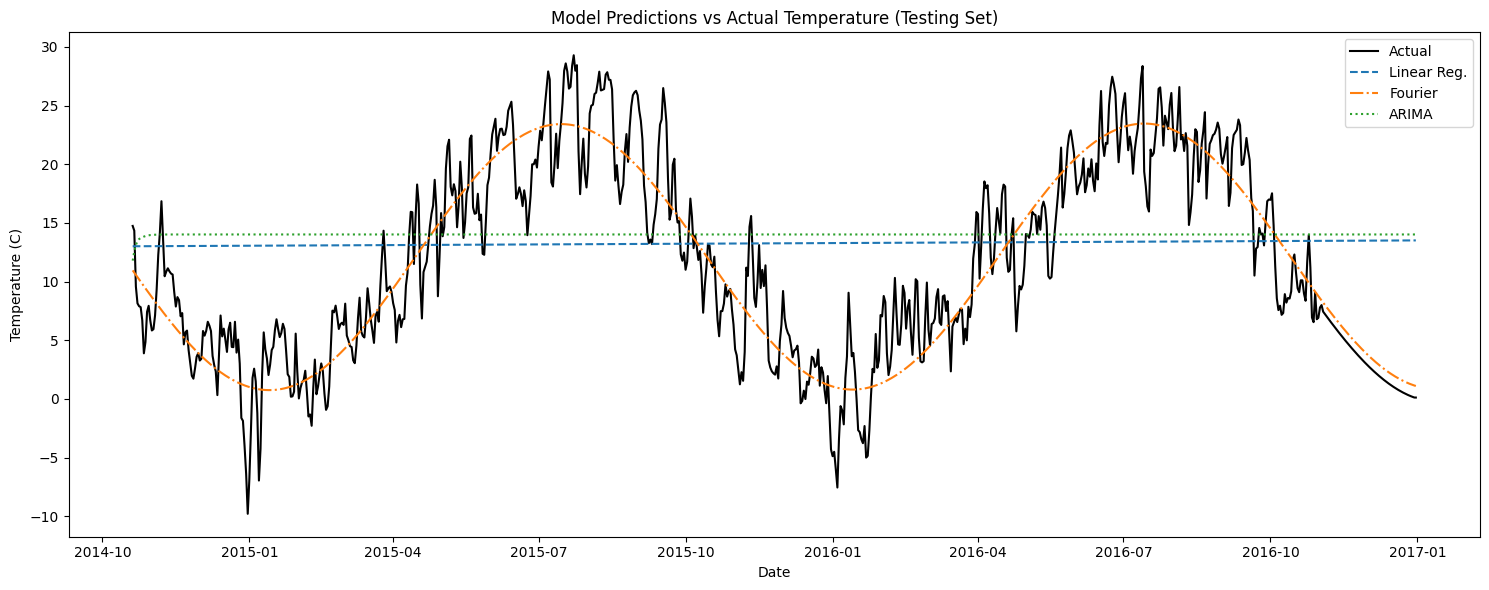

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

test_path = '/content/drive/MyDrive/weather_test_weather_history_project.csv'
test_df = pd.read_csv(test_path, parse_dates=['Formatted Date'])

lr_model = joblib.load('/content/drive/MyDrive/linear_regression_model_weather_history_project.pkl')
fourier_model = joblib.load('/content/drive/MyDrive/fourier_model_weather_history_project.pkl')
arima_model = joblib.load('/content/drive/MyDrive/arima_model_weather_history_project.pkl')

# predictions
# Linear Regression
test_lr_pred = lr_model.predict(test_df[['TimeIndex']])

# Fourier Series
test_df['sin'] = np.sin(2 * np.pi * test_df['TimeIndex'] / 365)
test_df['cos'] = np.cos(2 * np.pi * test_df['TimeIndex'] / 365)
test_fourier_pred = fourier_model.predict(test_df[['TimeIndex', 'sin', 'cos']])

# ARIMA
steps = len(test_df)
test_arima_pred = arima_model.forecast(steps=steps)

# Define evaluation function
def evaluate_model(true, pred):
    mse = mean_squared_error(true, pred)
    rmse = mse ** 0.5
    mape = mean_absolute_percentage_error(true, pred)
    r2 = r2_score(true, pred)
    return rmse, mape, r2

# Evaluate each model
true_values = test_df['Temperature (C)']
rmse_lr, mape_lr, r2_lr = evaluate_model(true_values, test_lr_pred)
rmse_fourier, mape_fourier, r2_fourier = evaluate_model(true_values, test_fourier_pred)
rmse_arima, mape_arima, r2_arima = evaluate_model(true_values, test_arima_pred)

# Print results
print("=== Testing Evaluation ===")
print(f"Linear Regression -> RMSE: {rmse_lr:.4f}, MAPE: {mape_lr:.4f}, R²: {r2_lr:.4f}")
print(f"Fourier Series    -> RMSE: {rmse_fourier:.4f}, MAPE: {mape_fourier:.4f}, R²: {r2_fourier:.4f}")
print(f"ARIMA             -> RMSE: {rmse_arima:.4f}, MAPE: {mape_arima:.4f}, R²: {r2_arima:.4f}")

# Plot predictions
plt.figure(figsize=(15, 6))
plt.plot(test_df['Formatted Date'], true_values, label='Actual', color='black')
plt.plot(test_df['Formatted Date'], test_lr_pred, label='Linear Reg.', linestyle='--')
plt.plot(test_df['Formatted Date'], test_fourier_pred, label='Fourier', linestyle='-.')
plt.plot(test_df['Formatted Date'], test_arima_pred, label='ARIMA', linestyle=':')
plt.title('Model Predictions vs Actual Temperature (Testing Set)')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.legend()
plt.tight_layout()
plt.show()

### 3.2 visualizations

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<Figure size 1400x1000 with 0 Axes>

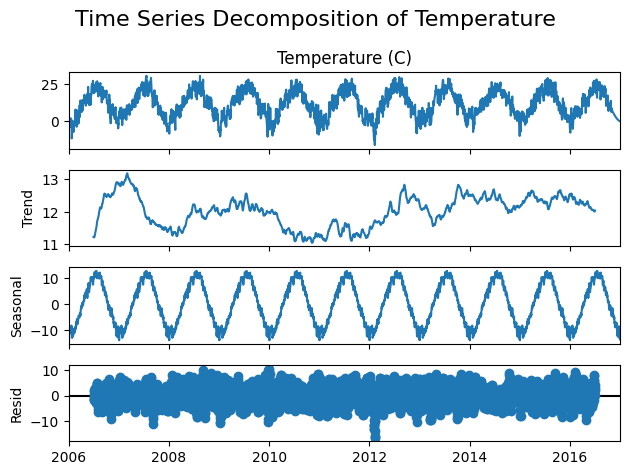

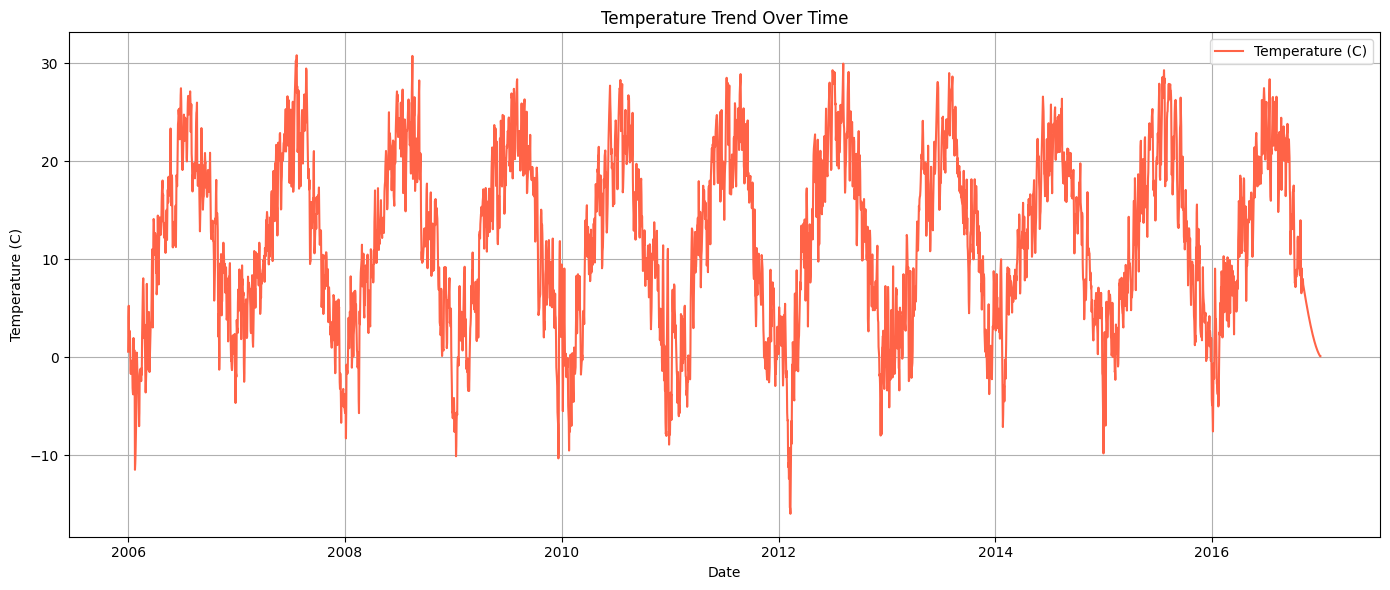

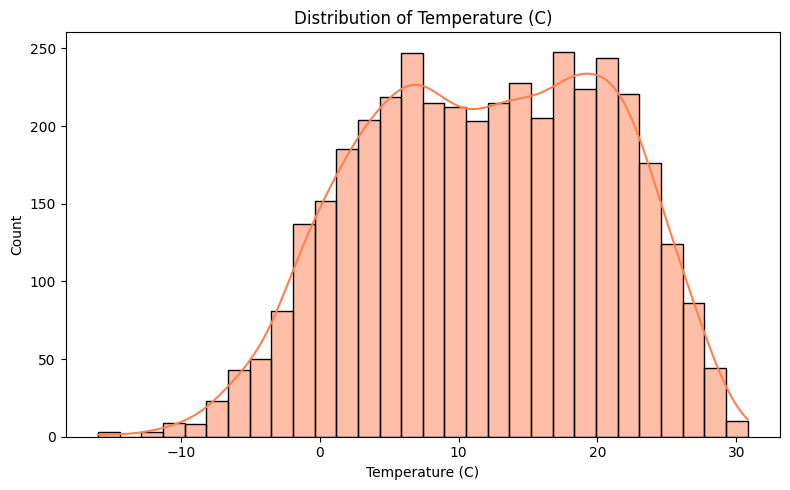

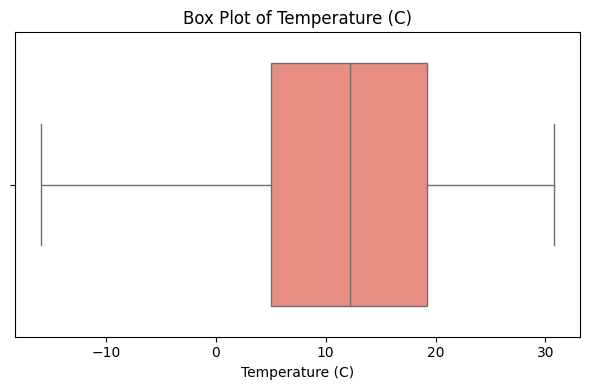

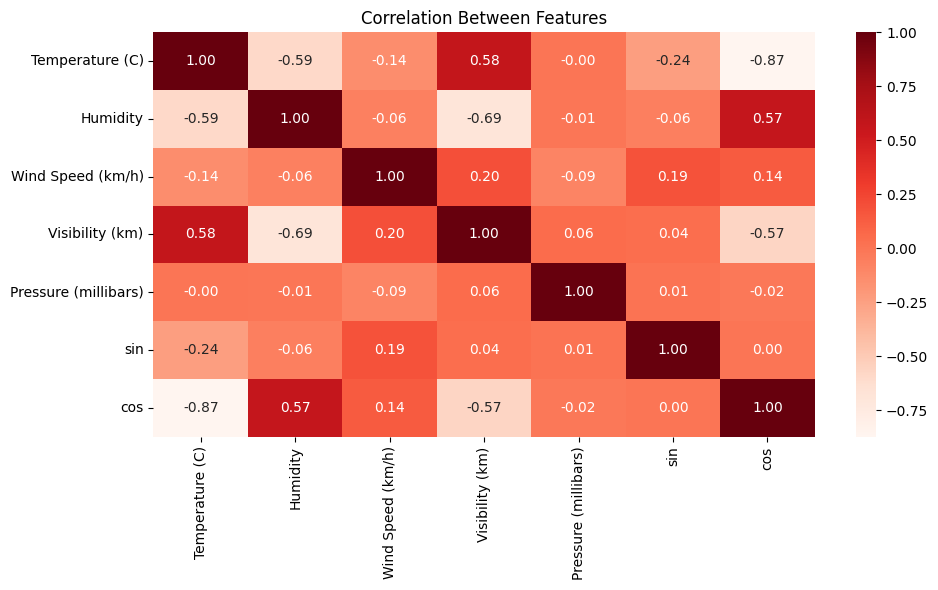

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

# Load the cleaned dataset
file_path = '/content/drive/MyDrive/weather_daily_fourier_weather_history_project.csv'
df = pd.read_csv(file_path, parse_dates=['Formatted Date'])

# Set the datetime column as index for time series operations
df.set_index('Formatted Date', inplace=True)

# Perform time series decomposition on the target column (Temperature)
decomposition = seasonal_decompose(df['Temperature (C)'], model='additive', period=365)

# Plot trend, seasonality, and residuals
plt.figure(figsize=(14, 10))
decomposition.plot()
plt.suptitle("Time Series Decomposition of Temperature", fontsize=16)
plt.tight_layout()
plt.show()

# Line plot to show how temperature changes over time
plt.figure(figsize=(14, 6))
plt.plot(df.index, df['Temperature (C)'], label='Temperature (C)', color='tomato')
plt.title('Temperature Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Histogram to show the distribution of temperature
plt.figure(figsize=(8, 5))
sns.histplot(df['Temperature (C)'], bins=30, kde=True, color='coral')
plt.title('Distribution of Temperature (C)')
plt.xlabel('Temperature (C)')
plt.tight_layout()
plt.show()

# Box plot to explore outliers in temperature
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Temperature (C)'], color='salmon')
plt.title('Box Plot of Temperature (C)')
plt.tight_layout()
plt.show()

# Correlation heatmap to show relationships between numeric features
plt.figure(figsize=(10, 6))
sns.heatmap(df.drop(columns=['TimeIndex']).corr(), annot=True, cmap='Reds', fmt=".2f")
plt.title('Correlation Between Features')
plt.tight_layout()
plt.show()

## 4. Trained Model Live Demo

### 4.1 Fourier And Linear live demo

In [ ]:
import numpy as np
import pandas as pd
from datetime import datetime
import joblib
from google.colab import drive

drive.mount('/content/drive')

# Load trained models
fourier_model = joblib.load('/content/drive/MyDrive/fourier_model_weather_history_project.pkl')
linear_model = joblib.load('/content/drive/MyDrive/linear_regression_model_weather_history_project.pkl')

# Ask the user to input a date
user_date_str = input("Enter a date (YYYY-MM-DD): ")

try:
    # Parse the input date
    user_date = pd.to_datetime(user_date_str)
    base_date = pd.to_datetime("2005-12-31")
    time_index = (user_date - base_date).days

    if time_index < 0:
        print("Error: Date is before the dataset range.")
    else:
        # Create features for both models
        sin_val = np.sin(2 * np.pi * time_index / 365)
        cos_val = np.cos(2 * np.pi * time_index / 365)

        # For Fourier model
        input_fourier = pd.DataFrame([[time_index, sin_val, cos_val]], columns=['TimeIndex', 'sin', 'cos'])
        temp_fourier = fourier_model.predict(input_fourier)[0]

        # For Linear Regression model
        input_linear = pd.DataFrame([[time_index]], columns=['TimeIndex'])
        temp_linear = linear_model.predict(input_linear)[0]

        # Display predictions
        print(f"\nPredictions for {user_date_str}:")
        print(f"Fourier Model Temperature: {temp_fourier:.2f} °C")
        print(f"Linear Regression Temperature: {temp_linear:.2f} °C")

except ValueError:
    print("Invalid date format. Please use YYYY-MM-DD.")

### 4.1 ARIMA live demo

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import necessary libraries
import pandas as pd
import numpy as np
import joblib
from datetime import datetime
from statsmodels.tsa.arima.model import ARIMAResults

# Load the trained ARIMA model
arima_model = joblib.load('/content/drive/MyDrive/arima_model_weather_history_project.pkl')

# Load training dataset to get the last known date
train_df = pd.read_csv('/content/drive/MyDrive/weather_train_weather_history_project.csv', parse_dates=['Formatted Date'])
train_df['Formatted Date'] = pd.to_datetime(train_df['Formatted Date'])
train_df.set_index('Formatted Date', inplace=True)

# Remove timezone info to avoid tz-aware vs tz-naive error
train_df.index = train_df.index.tz_localize(None)

# Ask for future date input
user_input = input("Enter a future date (YYYY-MM-DD): ")
user_date = pd.to_datetime(user_input)

# Compare user input to last training date
last_train_date = train_df.index[-1]

if user_date <= last_train_date:
    print("Please enter a date AFTER the training data ends:", last_train_date.date())
else:
    # Forecast how many days ahead
    days_ahead = (user_date - last_train_date).days
    prediction = arima_model.forecast(steps=days_ahead)
    predicted_temp = prediction.iloc[-1]
    print(f"Predicted temperature on {user_input} is: {predicted_temp:.2f} °C")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Enter a future date (YYYY-MM-DD): 2017-05-13
Predicted temperature on 2017-05-13 is: 14.02 °C
